# Entropy Calculation

In [33]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [34]:
from qss import entropy
from qss.distributions import prepare_2D_lattice_data, DistType

## Load $\mu$

In [35]:
mu_df = pd.read_csv("chemical_potential_results.csv")

In [36]:
n = np.unique(mu_df["n"])
distro = np.unique(mu_df["distro"])
k_BT = np.unique(mu_df["k_BT"])
H_a = np.unique(mu_df["H_a"])
mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])

## 2D Lattice

In [37]:
N = 100
t = -1
t_prim = 0.25
# t_prim = 0

kx = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi
ky = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi

e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

## Entropy

In [38]:
mu_df = pd.read_csv("chemical_potential_results.csv")
mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])

entropy_df = entropy(mu_df, e_k)


# Entropy

#### $\frac{S} {k_B N} = f(n)$

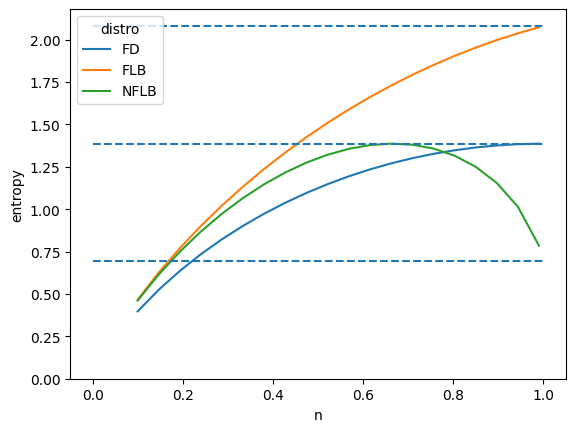

In [42]:
data = entropy_df.loc[(distro, n, k_BT[-1], H_a[0]), :]
fig,ax = plt.subplots()
sns.lineplot(data= data, x="n", y="entropy", hue="distro", markers=True, ax=ax)
ax.set_ylim(0,3*np.log(2)+0.1)
ax.hlines(y=[np.log(2),2* np.log(2), 3*np.log(2)], xmax=1,xmin=0, linestyles="--")